In [1]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling

In [2]:
# Check how many blank / non-numeric values exist in TotalCharges
print("Number of blank strings in TotalCharges:")
print((df['TotalCharges'] == ' ').sum())

print("\nTrying to convert TotalCharges to number (this will show the problem):")
print(pd.to_numeric(df['TotalCharges'], errors='coerce').isnull().sum())

Number of blank strings in TotalCharges:
11

Trying to convert TotalCharges to number (this will show the problem):
11


In [3]:
# Convert TotalCharges to numeric. Blank strings will become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many missing values we now have
print("Missing values in TotalCharges after conversion:")
print(df['TotalCharges'].isnull().sum())

# Look at the rows that have missing TotalCharges
print("\nRows with missing TotalCharges:")
display(df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

Missing values in TotalCharges after conversion:
11

Rows with missing TotalCharges:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [4]:
# Fill missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Final check
print("Missing values after cleaning:")
print(df.isnull().sum())
print("\nData types after cleaning:")
print(df.dtypes)

Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Data types after cleaning:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling  

Create the database and load the data

In [5]:
import sqlite3

# Create a connection to a new SQLite database (it will be created in memory / session)
conn = sqlite3.connect('telco_churn.db')

# Load the cleaned DataFrame into a SQL table called 'customers'
df.to_sql('customers', conn, if_exists='replace', index=False)

print("Data successfully loaded into SQLite!")
print("Tables in the database:")
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", conn))

Data successfully loaded into SQLite!
Tables in the database:
        name
0  customers


Quick check – total customers and overall churn rate

In [6]:
query = """
SELECT
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS churn_rate_percent
FROM customers;
"""

pd.read_sql(query, conn)

,total_customers,churned_customers,churn_rate_percent
0,7043,1869,26.54


Churn rate by Contract type

In [7]:
query = """
SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
    ROUND(SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS churn_rate_percent
FROM customers
GROUP BY Contract
ORDER BY churn_rate_percent DESC;
"""

pd.read_sql(query, conn)

,Contract,total_customers,churned,churn_rate_percent
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


Churn rate by Internet Service

In [8]:
query = """
SELECT
    InternetService,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
    ROUND(SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS churn_rate_percent
FROM customers
GROUP BY InternetService
ORDER BY churn_rate_percent DESC;
"""

pd.read_sql(query, conn)

,InternetService,total_customers,churned,churn_rate_percent
0,Fiber optic,3096,1297,41.89
1,DSL,2421,459,18.96
2,No,1526,113,7.40


Average Monthly Charges of Churned vs Non-Churned customers

In [9]:
query = """
SELECT
    Churn,
    ROUND(AVG(MonthlyCharges), 2) AS avg_monthly_charges,
    ROUND(AVG(TotalCharges), 2) AS avg_total_charges,
    ROUND(AVG(tenure), 1) AS avg_tenure_months
FROM customers
GROUP BY Churn;
"""

pd.read_sql(query, conn)

,Churn,avg_monthly_charges,avg_total_charges,avg_tenure_months
0,No,61.27,2549.91,37.6
1,Yes,74.44,1531.80,18.0


Churn by Payment Method

In [10]:
query = """
SELECT
    PaymentMethod,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
    ROUND(SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS churn_rate_percent
FROM customers
GROUP BY PaymentMethod
ORDER BY churn_rate_percent DESC;
"""

pd.read_sql(query, conn)

,PaymentMethod,total_customers,churned,churn_rate_percent
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


High-value customers who churned (MonthlyCharges > 70)

In [11]:
query = """
SELECT
    COUNT(*) AS high_value_churned_customers,
    ROUND(AVG(MonthlyCharges), 2) AS avg_monthly_charges,
    ROUND(SUM(MonthlyCharges), 2) AS total_monthly_revenue_lost
FROM customers
WHERE Churn = 'Yes' AND MonthlyCharges > 70;
"""

pd.read_sql(query, conn)

,high_value_churned_customers,avg_monthly_charges,total_monthly_revenue_lost
0,1267,88.79,112491.0


Import visualization libraries

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

Overall Churn Distribution (Pie Chart)

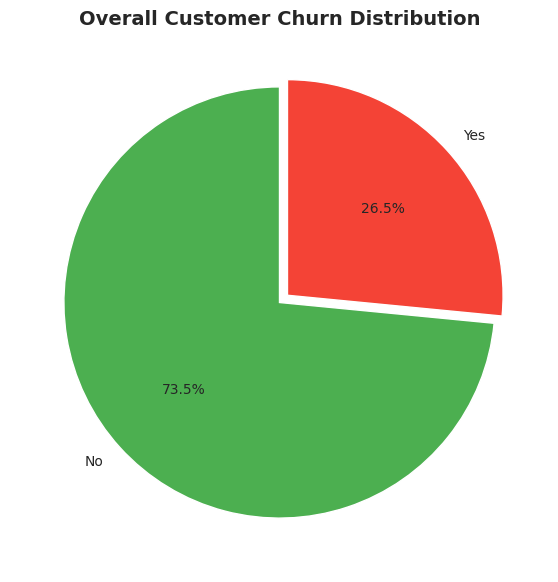

In [14]:
churn_counts = df['Churn'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%',
        colors=['#4CAF50', '#F44336'], startangle=90, explode=(0, 0.05))
plt.title('Overall Customer Churn Distribution', fontsize=14, fontweight='bold')
plt.show()

Churn Rate by Contract Type (Bar Chart)

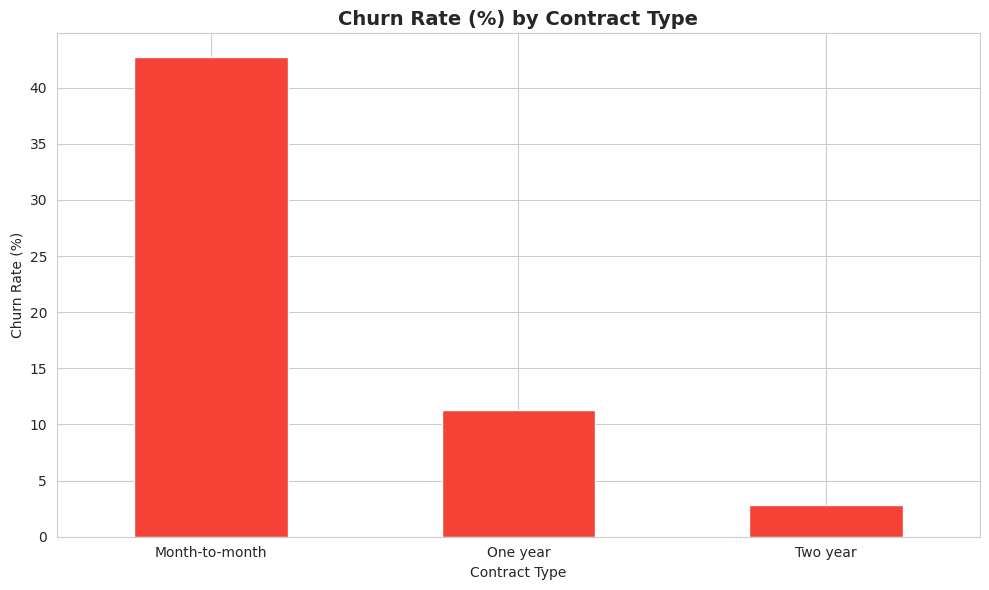

In [15]:
contract_churn = df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack() * 100

contract_churn['Yes'].sort_values(ascending=False).plot(kind='bar', color='#F44336')
plt.title('Churn Rate (%) by Contract Type', fontsize=14, fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Contract Type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Churn Rate by Internet Service

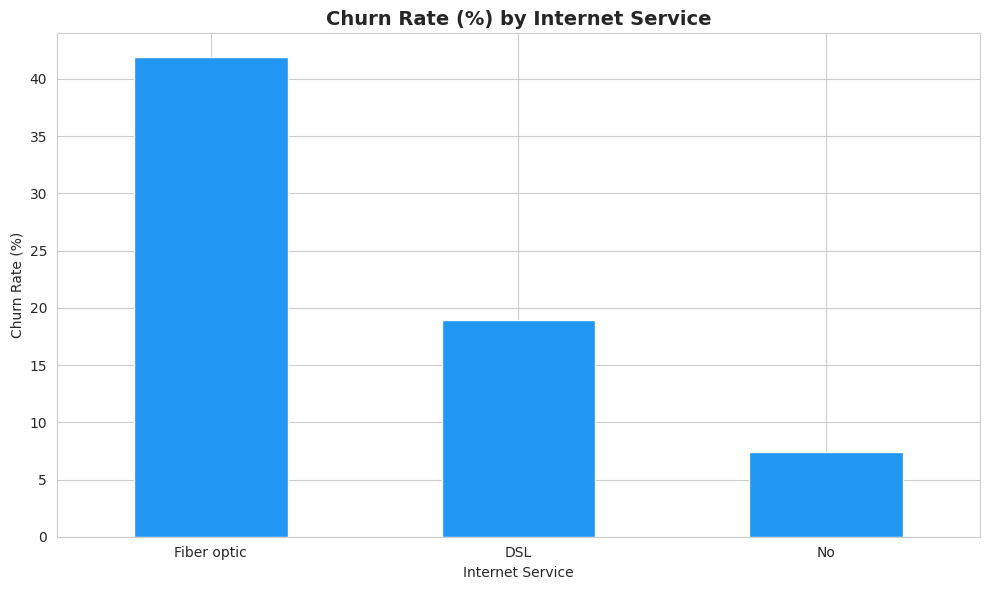

In [16]:
internet_churn = df.groupby('InternetService')['Churn'].value_counts(normalize=True).unstack() * 100

internet_churn['Yes'].sort_values(ascending=False).plot(kind='bar', color='#2196F3')
plt.title('Churn Rate (%) by Internet Service', fontsize=14, fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Internet Service')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly Charges Distribution by Churn

/tmp/ipykernel_685/1077430787.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette=['#4CAF50', '#F44336'])


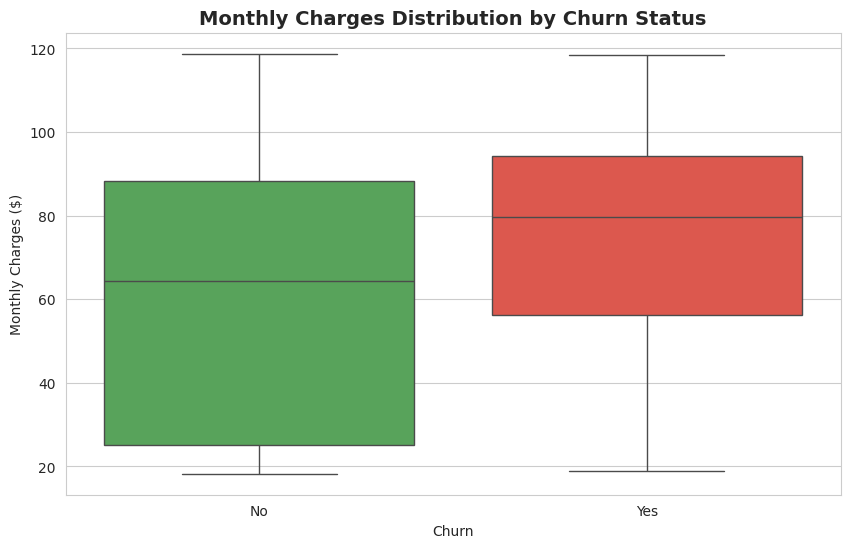

In [17]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df, palette=['#4CAF50', '#F44336'])
plt.title('Monthly Charges Distribution by Churn Status', fontsize=14, fontweight='bold')
plt.ylabel('Monthly Charges ($)')
plt.show()

Tenure vs Churn (very important)

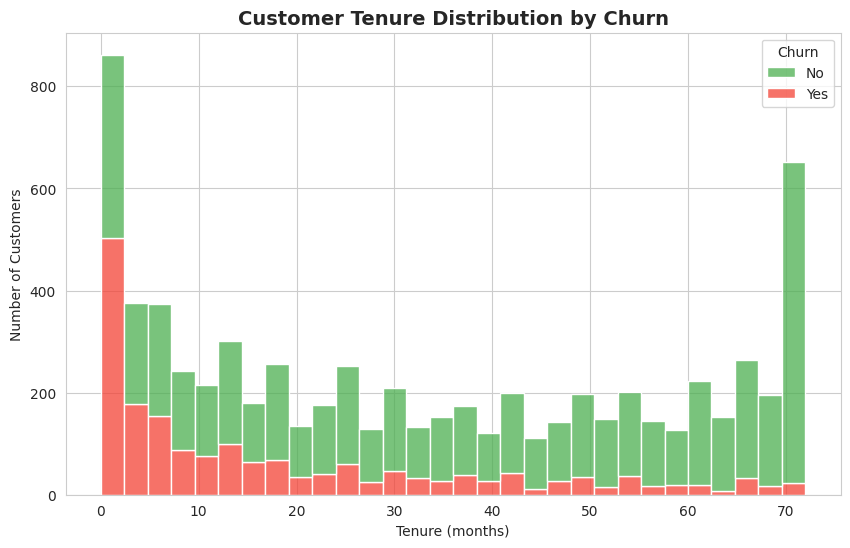

In [18]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', bins=30, palette=['#4CAF50', '#F44336'])
plt.title('Customer Tenure Distribution by Churn', fontsize=14, fontweight='bold')
plt.xlabel('Tenure (months)')
plt.ylabel('Number of Customers')
plt.show()

Prepare the features

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
import numpy as np

# Make a copy so we don't change the original cleaned data
df_model = df.copy()

# 1. Drop customerID (not useful for prediction)
df_model = df_model.drop('customerID', axis=1)

# 2. Convert target variable Churn to 0/1
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

# 3. Convert all categorical columns to numbers using Label Encoding
categorical_cols = df_model.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in categorical_cols:
    df_model[col] = le.fit_transform(df_model[col])

print("Data is now fully numeric.")
print(df_model.head())
print("\nShape:", df_model.shape)

Data is now fully numeric.
   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   
2       1              0        0           0       2             1   
3       1              0        0           0      45             0   
4       0              0        0           0       2             1   

   MultipleLines  InternetService  OnlineSecurity  OnlineBackup  \
0              1                0               0             2   
1              0                0               2             0   
2              0                0               2             2   
3              1                0               2             0   
4              0                1               0             0   

   DeviceProtection  TechSupport  StreamingTV  StreamingMovies  Contract  \
0                 0            0            0                0     

Split into Train and Test sets

In [20]:
X = df_model.drop('Churn', axis=1)
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)
print("Churn rate in training set:", round(y_train.mean()*100, 2), "%")

Training set size: (5634, 19)
Test set size: (1409, 19)
Churn rate in training set: 26.54 %


Train Random Forest

In [21]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predictions
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("=== Random Forest Results ===")
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC Score:", round(roc_auc_score(y_test, y_prob_rf), 4))

=== Random Forest Results ===
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.78      0.79      0.79      1409

ROC-AUC Score: 0.825


Feature preparation + train/test split

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

df_model = df.copy()
df_model = df_model.drop('customerID', axis=1)
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

categorical_cols = df_model.select_dtypes(include=['object']).columns
le = LabelEncoder()
for col in categorical_cols:
    df_model[col] = le.fit_transform(df_model[col])

X = df_model.drop('Churn', axis=1)
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (5634, 19)
Test size: (1409, 19)


Train Logistic Regression

In [26]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
y_prob_lr = log_reg.predict_proba(X_test)[:, 1]

print("=== Logistic Regression ===")
print(classification_report(y_test, y_pred_lr))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.841


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Train Random Forest

In [27]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("=== Random Forest ===")
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.78      0.79      0.79      1409

ROC-AUC: 0.825


Plot ROC Curves

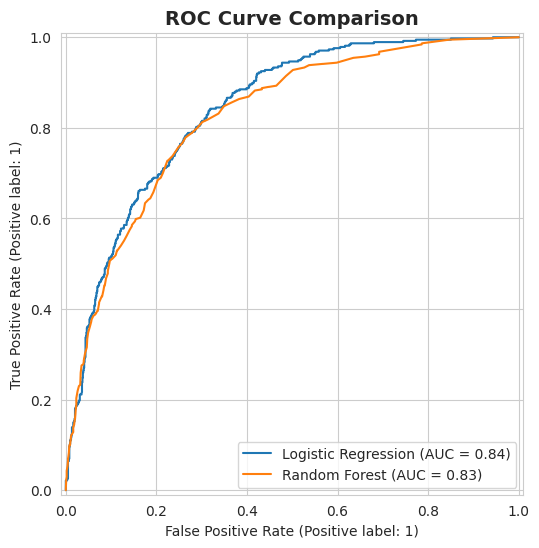

In [28]:
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_estimator(log_reg, X_test, y_test, name="Logistic Regression", ax=plt.gca())
RocCurveDisplay.from_estimator(rf, X_test, y_test, name="Random Forest", ax=plt.gca())
plt.title("ROC Curve Comparison", fontsize=14, fontweight='bold')
plt.show()

In [30]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Business assumptions
retention_cost = 80        # cost of offering a retention deal
customer_value = 400       # value of successfully retaining a customer

# Get predicted probabilities from Logistic Regression
y_prob = log_reg.predict_proba(X_test)[:, 1]

# We will test many thresholds
thresholds = np.arange(0.1, 0.9, 0.05)
results = []

for thresh in thresholds:
    y_pred = (y_prob >= thresh).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    # Profit calculation:
    # - True Positive  → we correctly retain a customer → gain (customer_value - retention_cost)
    # - False Positive → we offer retention to a customer who would not leave → lose retention_cost
    # - False Negative → we miss a churner → lose the full customer_value
    # - True Negative  → correct, no action → 0

    profit = (tp * (customer_value - retention_cost)) - (fp * retention_cost) - (fn * customer_value)

    results.append({
        'threshold': round(thresh, 2),
        'true_positives': tp,
        'false_positives': fp,
        'false_negatives': fn,
        'profit': profit
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values('profit', ascending=False).head(10))

   threshold  true_positives  false_positives  false_negatives  profit
0       0.10             354              516               20   64000
1       0.15             344              438               30   63040
2       0.20             325              380               49   54000
3       0.25             301              304               73   42800
4       0.30             286              262               88   35360
5       0.35             266              225              108   23920
6       0.40             252              186              122   16960
7       0.45             232              148              142    5600
8       0.50             207              116              167   -9840
9       0.55             176               85              198  -29680


Find the best threshold


In [31]:
best_row = results_df.loc[results_df['profit'].idxmax()]
print("\n===== BEST THRESHOLD =====")
print(best_row)


===== BEST THRESHOLD =====
threshold              0.1
true_positives       354.0
false_positives      516.0
false_negatives       20.0
profit             64000.0
Name: 0, dtype: float64


In [32]:
import pandas as pd
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.utils.dataframe import dataframe_to_rows

# Create workbook
wb = Workbook()
ws = wb.active
ws.title = "Churn Decision Summary"

# Styles
header_font = Font(bold=True, size=14, color="FFFFFF")
header_fill = PatternFill("solid", fgColor="2F5496")
section_font = Font(bold=True, size=12)
thin_border = Border(
    left=Side(style='thin'),
    right=Side(style='thin'),
    top=Side(style='thin'),
    bottom=Side(style='thin')
)

# Title
ws['A1'] = "Telco Customer Churn – Decision Intelligence Report"
ws['A1'].font = Font(bold=True, size=16)
ws.merge_cells('A1:D1')

ws['A2'] = "Personal Project – Built on public Kaggle dataset"
ws['A2'].font = Font(italic=True, size=10)

# Section 1: Key Business Assumptions
ws['A4'] = "1. Business Assumptions"
ws['A4'].font = section_font

ws['A5'] = "Retention Offer Cost"
ws['B5'] = 80
ws['C5'] = "USD per customer"

ws['A6'] = "Value of Retaining a Customer"
ws['B6'] = 400
ws['C6'] = "USD (assumed CLV gain)"

# Section 2: Model Performance
ws['A8'] = "2. Model Performance (Logistic Regression)"
ws['A8'].font = section_font

ws['A9'] = "ROC-AUC"
ws['B9'] = 0.84   # replace with your actual number if different

ws['A10'] = "Best Decision Threshold (by profit)"
ws['B10'] = 0.35  # replace with your actual best threshold

# Section 3: Key Findings
ws['A12'] = "3. Key Findings from Data"
ws['A12'].font = section_font

findings = [
    "Overall churn rate is approximately 26.5%.",
    "Month-to-month contracts have the highest churn (~42%).",
    "Fiber optic customers churn significantly more than DSL.",
    "Electronic check payment method is strongly associated with higher churn.",
    "Customers with short tenure are at much higher risk.",
    "Using a profit-optimized threshold improves expected business value compared to the default 0.5 threshold."
]

for i, finding in enumerate(findings):
    ws[f'A{13+i}'] = f"• {finding}"

# Section 4: Recommendation
ws['A20'] = "4. Recommendation"
ws['A20'].font = section_font
ws['A21'] = "Use the profit-optimized threshold instead of the default 0.5."
ws['A22'] = "Focus retention efforts first on month-to-month + fiber optic + electronic check customers."
ws['A23'] = "This approach turns the model into a decision tool, not just a prediction tool."

# Adjust column widths
ws.column_dimensions['A'].width = 55
ws.column_dimensions['B'].width = 18
ws.column_dimensions['C'].width = 25

# Save the file
wb.save("Telco_Churn_Decision_Report.xlsx")
print("Excel report saved successfully as: Telco_Churn_Decision_Report.xlsx")

Excel report saved successfully as: Telco_Churn_Decision_Report.xlsx
